# Modeling Yourself

*The Mathematics of Machine Intelligence · Chapter 30*

How does a system tell what it did from what merely happened, and what information might help it do so?

These pages illustrate the mathematics. Read the saved figures and calculations in order, or open [the interactive browser edition](reader.html) to change the examples. No code editing is needed. Every figure is computed from the chapter's own equations or from a disclosed simulation; a simulation is not a measurement, and the mathematics of a brain is a model.

When a system subtracts a prediction of its own move, check the prediction's gain and show the operator both the prediction and the observation before treating the leftover as the world.

<details><summary>Reproducing these calculations</summary>

The optional calculation cells use Python with NumPy and Matplotlib. All inputs, random seeds and functions are included in this file. The figures below are saved, so running these cells is optional.

</details>

In [1]:
import io
import math
import re
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from cycler import cycler
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.titlesize': 13, 'axes.labelsize': 11, 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#7d8588', 'axes.labelcolor': '#172a3b', 'text.color': '#172a3b', 'xtick.color': '#52606b', 'ytick.color': '#52606b', 'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white', 'grid.alpha': 0.2, 'lines.linewidth': 2, 'svg.fonttype': 'path', 'axes.unicode_minus': False})
plt.rcParams['axes.prop_cycle'] = cycler(color=['#136f75', '#b77518', '#334c72', '#aa4e37', '#677341'])

def clean_display_text(text):
    """Remove signed zero only after an explicitly formatted value rounds to zero."""
    return re.sub(r"(?<![\w.])-(?:0+(?:\.0*)?|\.0+)(?:[eE][+-]?\d+)?(?![\w.])", "0", text)


def display_value(value):
    """One display policy for readers, saved notebooks and skill references."""
    if hasattr(value, "item") and getattr(value, "size", 1) == 1:
        value = value.item()
    if isinstance(value, float):
        if not math.isfinite(value):
            raise ValueError("Return undefined or infinity as a labeled string, not a nonfinite JSON value")
        return "0" if value == 0 else f"{value:.6g}"
    if isinstance(value, str):
        return clean_display_text(value)
    if isinstance(value, (list, tuple)):
        opening, closing = ("(", ")") if isinstance(value, tuple) else ("[", "]")
        return opening + ", ".join(str(display_value(v)) for v in value) + closing
    if isinstance(value, dict):
        return "{" + ", ".join(str(k) + ": " + str(display_value(v)) for k, v in value.items()) + "}"
    return value


"""Chapter 30, Modeling Yourself: executable mathematics and reader-facing teaching content."""
import math
import numpy as np
import matplotlib.pyplot as plt
NAVY = '#17324d'
TEAL = '#147d86'
GOLD = '#d8a23c'
DARK_GOLD = '#8a5a0f'
TERRA = '#bf6045'
GREY = '#7d8588'

def sig(value, digits=3):
    """Three significant figures; values that are zero up to round-off show as 0."""
    value = float(value)
    if abs(value) < 1e-12:
        return '0'
    return f'{value:.{digits}g}'

def panels():
    fig, axes = plt.subplots(1, 2, figsize=(8, 4.2), layout='constrained')
    for ax in axes:
        ax.grid(alpha=0.15)
    return (fig, axes)

def tag(ax, x, y, text, **kwargs):
    """A label with a white backing so it stays legible over lines."""
    kwargs.setdefault('fontsize', 10)
    kwargs.setdefault('ha', 'center')
    ax.text(x, y, text, bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1.2, 'alpha': 0.9}, **kwargs)

def ring(ax, x, y):
    ax.plot([x], [y], marker='o', markersize=11, markerfacecolor='none', markeredgecolor=NAVY, markeredgewidth=2.2, zorder=6)

def leftover(turn, gain, outside=0.0):
    """Sensed change, predicted change and leftover for a movement of size turn (the movement's real effect equals turn)."""
    sensed = outside + turn
    predicted = gain * turn
    return (sensed, predicted, sensed - predicted)
GAINS = [0.8, 0.9, 1.0, 1.1]

def phantom_picture(turn=20, gain=0.9):
    sensed, predicted, e = leftover(turn, gain)
    fig, ax = panels()
    x = np.arange(3)
    bars = ax[0].bar(x, [sensed, predicted, e], color=[GREY, TEAL, TERRA], width=0.6)
    for bar, v in zip(bars, [sensed, predicted, e]):
        tag(ax[0], bar.get_x() + bar.get_width() / 2, v + (1.0 if v >= 0 else -1.0), sig(v), va='bottom' if v >= 0 else 'top')
    ax[0].axhline(0, color=GREY, linewidth=1)
    ax[0].set_xticks(x, ['sensed\nchange', 'predicted\nchange', 'leftover'])
    ax[0].set(ylabel='degrees', title=f'Camera turns {sig(turn)} degrees, gain {sig(gain)}', ylim=(-8, 36))
    grid = np.linspace(0, 30, 61)
    for g, colour, style in [(0.8, GOLD, 'dashed'), (0.9, TEAL, 'solid'), (1.0, GREY, 'dotted'), (1.1, TERRA, 'dashed')]:
        chosen = g == gain
        ax[1].plot(grid, [leftover(t, g)[2] for t in grid], color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'gain {g:g}')
    ring(ax[1], turn, e)
    ax[1].axhline(0, color=GREY, linewidth=1)
    ax[1].set(xlabel='turn of the camera (degrees)', ylabel='leftover (degrees)', title='Phantom drift grows with the turn', ylim=(-4, 7))
    ax[1].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=4)
    if abs(e) < 1e-12:
        meaning = 'no leftover'
    elif e > 0:
        meaning = 'motion that never happened'
    else:
        meaning = 'motion missing from the report'
    metrics = {'Sensed change (degrees)': sig(sensed), 'Predicted change (degrees)': sig(predicted), 'Leftover (degrees)': sig(e), 'Leftover reads as': meaning}
    summary = f'Nothing outside moves, so the sensed change is {sig(sensed)}. With prediction gain {sig(gain)} the prediction is {sig(predicted)}, and the leftover {sig(e)} degrees is {meaning}. The leftover is {sig(1 - gain)} of the turn, so it grows in proportion to the movement.'
    calc = f'e = s_obs - f(c) = {sig(sensed)} - {sig(gain)} x {sig(turn)} = {sig(sensed)} - {sig(predicted)} = {sig(e)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
OUTSIDE_VALUES = [0, 1, 2]
THRESHOLDS = [0.5, 1.5]

def ambiguity_picture(gain=0.9, outside=0, threshold=0.5):
    turn = 10
    sensed, predicted, e = leftover(turn, gain, outside)
    fig, ax = panels()
    x = np.arange(3)
    bars = ax[0].bar(x, [sensed, predicted, e], color=[GREY, TEAL, TERRA], width=0.6)
    for bar, v in zip(bars, [sensed, predicted, e]):
        tag(ax[0], bar.get_x() + bar.get_width() / 2, v + 0.3, sig(v), va='bottom')
    ax[0].axhline(threshold, color=DARK_GOLD, linestyle='dashed', linewidth=1.5)
    tag(ax[0], 2.45, threshold + 0.9, 'alarm\nthreshold', fontsize=8, color=DARK_GOLD)
    ax[0].set_xticks(x, ['sensed\nchange', 'predicted\nchange', 'leftover'])
    ax[0].set(ylabel='degrees', title=f'10 degree turn, gain {sig(gain)}, outside motion {sig(outside)}', ylim=(0, 14.5))
    ax[0].title.set_fontsize(9)
    gg, ww = np.meshgrid(np.linspace(0.75, 1.15, 81), np.linspace(-0.4, 2.4, 81))
    ee = ww + turn * (1 - gg)
    ax[1].contourf(gg, ww, (np.abs(ee) > threshold).astype(float), levels=[-0.5, 0.5, 1.5], colors=['#e4f1f2', '#f3dcd5'])
    ax[1].contour(gg, ww, ee, levels=[e], colors=[NAVY], linestyles='dashed', linewidths=2)
    ax[1].scatter([g for g in GAINS for _ in OUTSIDE_VALUES], [w for _ in GAINS for w in OUTSIDE_VALUES], s=18, color=GREY, zorder=4)
    ring(ax[1], gain, outside)
    tag(ax[1], 0.8, 2.25, 'alarm (red)', fontsize=8, color=TERRA, ha='left')
    ax[1].set(xlabel='prediction gain', ylabel='outside motion (degrees)', title='Dashed: every cause with this leftover', ylim=(-0.4, 2.4))
    alarm = abs(e) > threshold
    truth = outside != 0
    if alarm and truth:
        verdict = 'true alarm'
    elif alarm:
        verdict = 'false alarm'
    elif truth:
        verdict = 'missed contact'
    else:
        verdict = 'correctly quiet'
    metrics = {'Leftover (degrees)': sig(e), 'Alarm raised': 'yes' if alarm else 'no', 'Outside motion present': 'yes' if truth else 'no', 'Outcome': verdict}
    summary = f"A leftover of {sig(e)} (in degrees) {('passes' if alarm else 'stays under')} the {sig(threshold)} degree threshold, so the alarm is {('raised' if alarm else 'quiet')}; with outside motion {sig(outside)} that is a {verdict}. Many pairs of gain and outside motion give the same leftover, so the leftover alone cannot say which is true."
    calc = f'e = w + 10 (1 - g) = {sig(outside)} + 10 x (1 - {sig(gain)}) = {sig(e)}. Same leftover for gain 0.9 with no outside motion and gain 1 with 1 degree of it.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
STROKE_HZ = 2.0
DELAYS = [0, 0.1, 0.2, 0.3, 0.4, 0.5]
ATTENUATIONS = [0.25, 0.5, 0.75]

def stroke(t, delay=0.0):
    return np.sin(2 * math.pi * STROKE_HZ * (t - delay))

def relative_error(delay):
    """RMS of (predicted stroke - arriving stroke), as a share of its largest possible value (the sine's)."""
    return abs(math.sin(math.pi * STROKE_HZ * delay))

def ticklish_share(delay, attenuation):
    """Share of the robot-only ticklishness left, if the touch is turned down in proportion to how well it matches the prediction."""
    return 1 - attenuation * (1 - relative_error(delay))

def delay_picture(delay=0.2, attenuation=0.5):
    fig, ax = panels()
    t = np.linspace(0, 1, 500)
    ax[0].plot(t, stroke(t), color=TEAL, linewidth=2, label='predicted')
    ax[0].plot(t, stroke(t, delay), color=TERRA, linewidth=2, linestyle='dashed', label='arriving')
    ax[0].fill_between(t, stroke(t), stroke(t, delay), color=GOLD, alpha=0.3, label='difference')
    ax[0].set(xlabel='time (seconds)', ylabel='stroke position (relative)', title=f'Delay of {sig(delay)} seconds', ylim=(-1.2, 1.2))
    ax[0].legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=3)
    d = np.linspace(0, 0.5, 101)
    ax[1].axvspan(0, 0.3, color=TEAL, alpha=0.07)
    tag(ax[1], 0.15, 0.26, 'delays used\nin the study', fontsize=8, color=TEAL)
    for k, colour, style in [(0.25, GREY, 'dotted'), (0.5, TEAL, 'solid'), (0.75, TERRA, 'dashed')]:
        chosen = k == attenuation
        ax[1].plot(d, [ticklish_share(x, k) for x in d], color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'k = {k:g}')
    ring(ax[1], delay, ticklish_share(delay, attenuation))
    ax[1].set(xlabel='delay (seconds)', ylabel='share of robot-only ticklishness', title='Sketch: ticklishness against delay', ylim=(0.2, 1.05))
    ax[1].legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=3)
    err = relative_error(delay)
    share = ticklish_share(delay, attenuation)
    metrics = {'Prediction error (share of its largest)': sig(err), 'Share of robot-only ticklishness': sig(share), 'Delay (seconds)': sig(delay)}
    summary = f'A {sig(delay)} second delay shifts a 2 per second stroke by {sig(delay * STROKE_HZ * 360)} degrees of its cycle, so the prediction error is {sig(err)} of its largest value. If the touch is turned down by {sig(attenuation)} when it matches the prediction, the share of robot-only ticklishness is {sig(share)}.'
    calc = f'Error = RMS of (sin(2 pi f t) - sin(2 pi f (t - d))) divided by sqrt(2) = |sin(pi f d)| = |sin(pi x 2 x {sig(delay)})| = {sig(err)}. Share = 1 - {sig(attenuation)} x (1 - {sig(err)}) = {sig(share)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def blend_position(forecast, senses, forecast_variance, sense_variance=1.0):
    gain = forecast_variance / (forecast_variance + sense_variance)
    return (gain, forecast + gain * (senses - forecast))
RATIOS = [0.25, 0.5, 1, 2, 3, 5, 9]
SENSES = [15, 20, 30]

def hand_picture(ratio=3, senses=20):
    forecast = 10.0
    gain, blend = blend_position(forecast, senses, ratio)
    fig, ax = panels()
    ax[0].hlines(0, 5, 32, color=GREY, linewidth=1)
    ax[0].scatter([forecast], [0], s=150, color=TERRA, zorder=3)
    ax[0].scatter([senses], [0], s=150, color=TEAL, zorder=3)
    ax[0].scatter([blend], [0], s=220, color=NAVY, marker='D', zorder=4)
    tag(ax[0], forecast, 0.22, f'forecast\n{forecast:g}', color=TERRA, fontsize=9)
    tag(ax[0], senses, 0.22, f'senses\n{sig(senses)}', color=TEAL, fontsize=9)
    tag(ax[0], blend, -0.3, f'blend {sig(blend)}', color=NAVY, fontsize=10)
    ax[0].set(xlim=(5, 32), ylim=(-0.7, 0.8), xlabel='hand position (cm)', title=f"Forecast variance is {sig(ratio)} times the senses'")
    ax[0].set_yticks([])
    grid = np.geomspace(0.2, 10, 80)
    for s, colour, style in [(15, GREY, 'dotted'), (20, TEAL, 'solid'), (30, TERRA, 'dashed')]:
        chosen = s == senses
        ax[1].plot(grid, [blend_position(forecast, s, r)[1] for r in grid], color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'senses say {s}')
    ring(ax[1], ratio, blend)
    ax[1].axvline(1, color=GREY, linewidth=1, linestyle='dotted')
    ax[1].set_xscale('log')
    ax[1].set_xticks([0.25, 0.5, 1, 2, 5, 9], ['0.25', '0.5', '1', '2', '5', '9'])
    ax[1].set(xlabel='forecast variance / senses variance', ylabel='blended position (cm)', title='The blend slides toward the senses')
    ax[1].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=3)
    metrics = {'Weight on the senses (Kalman gain)': sig(gain), 'Weight on the forecast': sig(1 - gain), 'Blended position (cm)': sig(blend)}
    summary = f"The forecast says {forecast:g} cm and the senses say {sig(senses)} cm. With the forecast's variance {sig(ratio)} times the senses', the senses get weight {sig(gain)} and the blend is {sig(blend)} cm. This weight is the Kalman gain, not the prediction gain of the camera example."
    calc = f'Gain = {sig(ratio)}/({sig(ratio)} + 1) = {sig(gain)}. Blend = {forecast:g} + {sig(gain)} x ({sig(senses)} - {forecast:g}) = {sig(blend)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
SEEN_DISTANCE_CM = 200.0
REPORTED_SHIFTS = {'in time': 24.1, 'out of time': 12.0}

def implied_weight(shift_cm, distance_cm=SEEN_DISTANCE_CM):
    return shift_cm / distance_cm

def implied_variance_ratio(weight):
    """If the felt location is a blend of own location and the seen body, the seen body's variance over the own location's variance."""
    if weight <= 0:
        return None
    return (1 - weight) / weight

def felt_location_picture(shift=24.1):
    w = implied_weight(shift)
    ratio = implied_variance_ratio(w)
    fig, ax = panels()
    ax[0].hlines(0, -25, 215, color=GREY, linewidth=1)
    ax[0].scatter([0, SEEN_DISTANCE_CM, shift], [0, 0, 0], s=[150, 150, 220], color=[TEAL, TERRA, NAVY], marker='o', zorder=3)
    tag(ax[0], 0, 0.22, 'own body\n0', color=TEAL, fontsize=9)
    tag(ax[0], SEEN_DISTANCE_CM, 0.22, 'seen body\n200 cm', color=TERRA, fontsize=9)
    tag(ax[0], max(shift, 25), -0.3, f'felt location {sig(shift)} cm', color=NAVY, fontsize=9, ha='left' if shift < 100 else 'center')
    ax[0].set(xlim=(-35, 225), ylim=(-0.7, 0.8), xlabel='distance toward the seen body (cm)', title='Where the felt location sits')
    ax[0].set_yticks([])
    grid = np.linspace(0.5, 60, 200)
    ax[1].plot(grid, [implied_weight(g) for g in grid], color=TEAL, linewidth=2, label='weight on the seen body')
    for name, value in REPORTED_SHIFTS.items():
        ax[1].scatter([value], [implied_weight(value)], s=60, color=TERRA, zorder=4)
        tag(ax[1], value + 1.5, implied_weight(value) - 0.035, f'{name}: {value:g} cm', fontsize=8, ha='left')
    ring(ax[1], shift, w)
    ax[1].set(xlabel='shift toward the seen body (cm)', ylabel='implied weight on the seen body', title='Shift as a share of the 200 cm', ylim=(0, 0.33))
    ax[1].legend(fontsize=9, loc='upper left')
    ratio_text = 'undefined (zero shift needs an infinite variance)' if ratio is None else sig(ratio)
    metrics = {'Shift (cm)': sig(shift), 'Implied weight on the seen body': sig(w), 'Implied variance ratio, seen body over own': ratio_text}
    summary = f"If the felt location were a blend of the own body (0 cm) and the seen body (200 cm), a shift of {sig(shift)} cm would mean a weight of {sig(w)} on the seen body. This is the companion's reading, not the study's claim, and the 12 cm shift was not a reliable shift from baseline."
    calc = f'Weight = shift / 200 = {sig(shift)}/200 = {sig(w)}. Variance ratio = (1 - w)/w = {ratio_text}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
TAU = 20.0
FEATURE_KINDS = ['raw pixels', 'learned features, static dropped', 'learned features, static at half size']
STATIC_WEIGHT = {FEATURE_KINDS[0]: 1.0, FEATURE_KINDS[1]: 0.0, FEATURE_KINDS[2]: 0.5}

def reward_parts(step, noise_share, kind, eta=1.0):
    """Reward per pixel, split into the door's part and the static's part: r = (eta/2) |predicted - actual|^2, averaged over the view."""
    door_error_sq = math.exp(-2 * step / TAU)
    door = eta / 2 * (1 - noise_share) * door_error_sq
    static = eta / 2 * noise_share * STATIC_WEIGHT[kind] ** 2 * 1.0
    return (door, static)

def curiosity_picture(noise_share=0.4, kind=FEATURE_KINDS[0]):
    steps = np.arange(0, 101)
    fig, ax = panels()
    door = np.array([reward_parts(s, noise_share, kind)[0] for s in steps])
    static = np.array([reward_parts(s, noise_share, kind)[1] for s in steps])
    ax[0].stackplot(steps, door, static, colors=[TEAL, TERRA], labels=['from the door', 'from the static'], alpha=0.85)
    ax[0].set(xlabel='training steps', ylabel='reward per pixel (eta = 1)', title=f'Static is {noise_share * 100:g} percent of the view', ylim=(0, 0.55))
    ax[0].legend(fontsize=9, loc='upper right')
    for name, colour, style in [(FEATURE_KINDS[0], TERRA, 'solid'), (FEATURE_KINDS[1], TEAL, 'solid'), (FEATURE_KINDS[2], GOLD, 'dashed')]:
        shares = []
        for s in steps:
            d, st = reward_parts(s, noise_share, name)
            shares.append(d / (d + st) if d + st > 1e-15 else np.nan)
        chosen = name == kind
        ax[1].plot(steps, shares, color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=name)
    ax[1].set(xlabel='training steps', ylabel='share of reward from the door', title='What the reward points at', ylim=(-0.03, 1.05))
    ax[1].legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=1)
    d100, s100 = reward_parts(100, noise_share, kind)
    d0, s0 = reward_parts(0, noise_share, kind)
    share100 = d100 / (d100 + s100) if d100 + s100 > 1e-15 else None
    metrics = {'Reward at step 0': sig(d0 + s0), 'Reward at step 100': sig(d100 + s100), 'Share from the door at step 100': 'undefined (no reward left)' if share100 is None else sig(share100)}
    summary = f"With {noise_share * 100:g} percent static and {kind}, the reward starts at {sig(d0 + s0)} and is {sig(d100 + s100)} at step 100. {('Static keeps the reward high however long the agent trains.' if s100 > 0.5 * (d100 + s100) else 'The door supplies most of what is left.')}"
    calc = f'r = (eta/2) x ({sig(1 - noise_share)} x e^(-2 t/{TAU:g}) + {sig(noise_share)} x {sig(STATIC_WEIGHT[kind] ** 2)}). At t = 100 the door part is {sig(d100)} and the static part is {sig(s100)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

## C30-D01: How much motion does a wrong prediction gain invent?

A camera turns while nothing outside moves. If its prediction of the turn is scaled wrong, how much phantom motion is left over?

The system holds a copy of its command and turns it into a predicted change. What the senses report minus that prediction is the leftover. If the gain is 0.9, ten percent of every turn is left over, so a bigger turn leaves a bigger leftover. Phantom drift is apparent motion left over when the gain is wrong.

$$
e=s_{\mathrm{obs}}-f(c)=w+\rho(a)-f(c)
$$

**Symbols:** e: the leftover: sensed minus predicted; s_obs: the sensed change after a movement, in degrees; f(c): the predicted effect of command c: the expected change times the prediction gain; w: the outside change (here 0); rho(a): the real effect of the movement a (here equal to the turn)

**Predict before looking:** Turn the camera 20 degrees with prediction gain 0.9 and nothing moving outside. Predict the leftover.

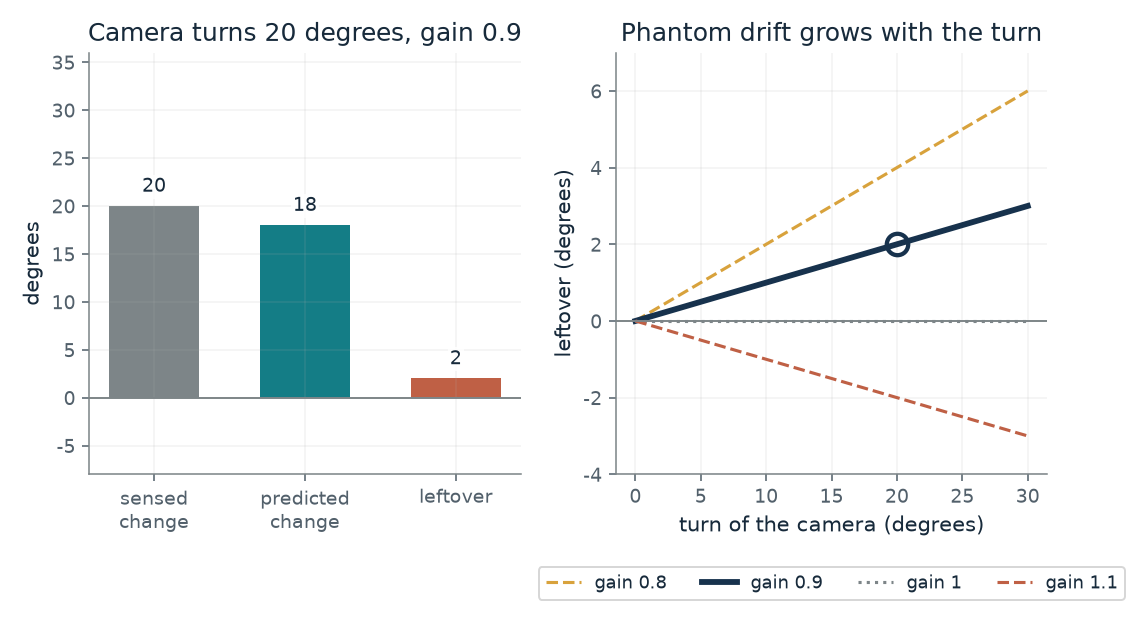

- **Sensed change (degrees):** 20
- **Predicted change (degrees):** 18
- **Leftover (degrees):** 2
- **Leftover reads as:** motion that never happened

Nothing outside moves, so the sensed change is 20. With prediction gain 0.9 the prediction is 18, and the leftover 2 degrees is motion that never happened. The leftover is 0.1 of the turn, so it grows in proportion to the movement.

e = s_obs - f(c) = 20 - 0.9 x 20 = 20 - 18 = 2.

In [2]:
figure, values, explanation = phantom_picture(**{'turn': 20, 'gain': 0.9})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How much motion does a wrong prediction gain invent?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Turn of the camera (degrees) = 20, Prediction gain = 0.9: The sensed change is 20, the prediction is 18, and the leftover is 2 degrees of apparent motion that never happened, twice the 1 degree at a 10 degree turn. At gain 1.0 it is zero, and at gain 1.1 the leftover turns negative.

**Takeaway:** A wrong prediction gain produces phantom drift that grows in proportion to the movement. The leftover is a mix of outside change and prediction error.

**Why it matters:** A system that subtracts a prediction of its own move gets a leftover it must read. If the prediction is off, the leftover looks like the world.

**In brains and behavior:** The von Holst and Mittelstaedt scheme: a command sends an inner copy (the efference copy) whose sign opposes the returning report, so the two cancel. The head-turned fly was their example of a flipped sign. This is their proposed scheme, and the chapter says it is a model.

**In machines:** The camera is a specification: this is what the leftover formula returns for a gain we chose. A real arm adds friction and model errors that can look like contact.

**Where it applies:** Effects add and the senses report without noise, as the chapter states. The prediction gain is the multiplier on a command's expected effect, which a designer chose.

**Check your understanding:** A camera turns 30 degrees with prediction gain 0.8 and nothing moves outside. What is the leftover?

<details><summary>Show the answer</summary>

30 - 0.8 x 30 = 6 degrees of phantom motion, one fifth of the turn.

</details>

*Source: Chapter 30, A fly with its head glued on upside down circled, lurched or froze. Book formula and the chapter's constructed camera example (10 and 20 degree turns at gain 0.9 give leftovers of 1 and 2). The other turns and gains are the companion's variations. The chapter says the example is constructed, not data.*

## C30-D02: Can the leftover tell a collision from a bad prediction?

A robot arm flags contact when the leftover passes a threshold. What else produces the same leftover?

The leftover is the outside change plus the effect of a wrong gain. For a 10 degree movement, the leftover is w + 10 (1 - g). Any pair of values on the dashed line gives the same leftover. A threshold turns the leftover into an alarm, but it cannot recover which cause was present, so it raises false alarms for a poor gain and misses contacts that are small.

$$
e=w+10\,(1-g),\qquad \text{alarm if } |e|>\text{threshold}
$$

**Symbols:** e: the leftover, in degrees; w: outside motion, in degrees; g: the prediction gain, applied to a 10 degree movement; threshold: the size of leftover that raises the alarm

**Predict before looking:** With gain 0.9 and no outside motion, predict the leftover and whether the alarm sounds with a threshold of 0.5.

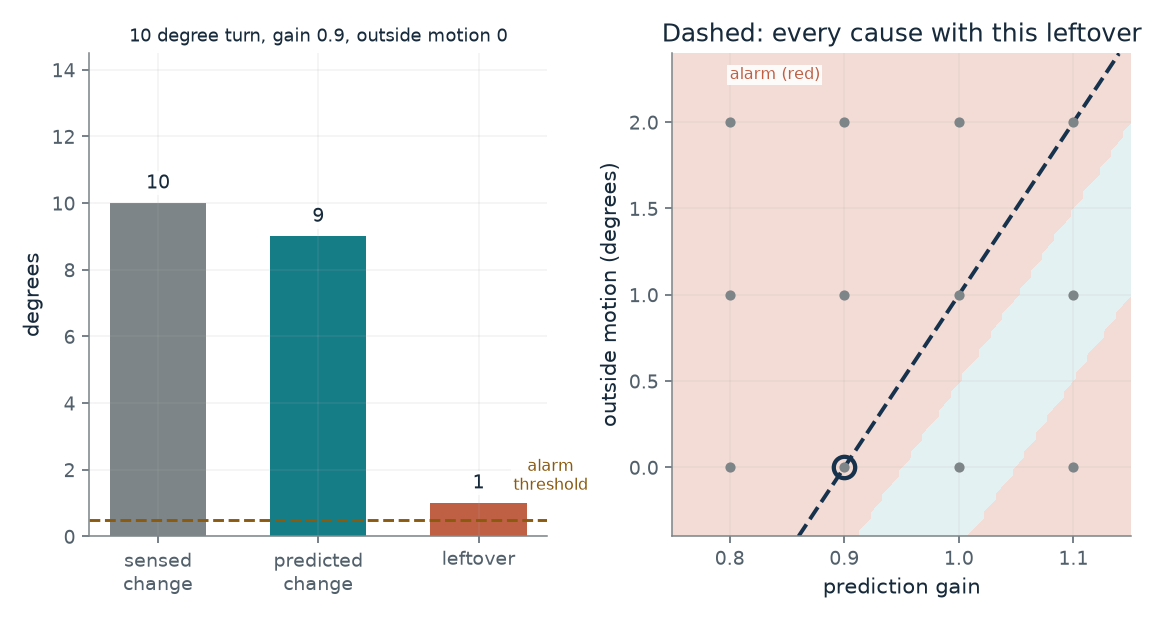

- **Leftover (degrees):** 1
- **Alarm raised:** yes
- **Outside motion present:** no
- **Outcome:** false alarm

A leftover of 1 (in degrees) passes the 0.5 degree threshold, so the alarm is raised; with outside motion 0 that is a false alarm. Many pairs of gain and outside motion give the same leftover, so the leftover alone cannot say which is true.

e = w + 10 (1 - g) = 0 + 10 x (1 - 0.9) = 1. Same leftover for gain 0.9 with no outside motion and gain 1 with 1 degree of it.

In [3]:
figure, values, explanation = ambiguity_picture(**{'gain': 0.9, 'outside': 0, 'threshold': 0.5})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Can the leftover tell a collision from a bad prediction?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Prediction gain = 0.9, Outside motion (degrees) = 0, Alarm threshold (degrees) = 0.5: The leftover is 1 degree, over the 0.5 threshold, so the alarm sounds although nothing touched the arm: a false alarm. The same leftover arises from gain 1.0 with 1 degree of outside motion, where the alarm is correct.

**Takeaway:** The leftover has more than one possible cause. A threshold converts it to an alarm that can be false, or can miss a contact smaller than the model error.

**Why it matters:** Something else must tell the causes apart. The chapter's proposal, its own and untested, is to show an operator both the prediction and the observation so a second sensor can be checked.

**In brains and behavior:** The chapter says ticklishness proposals do not show subtraction; this is an engineering contrast, not a claim about touch.

**In machines:** Collision detection by comparing commanded and expected torque is routine engineering, which the chapter attributes to a survey of 2017. Friction compensation and thresholds are its remedies for modeling errors.

**Where it applies:** One 10 degree movement, effects that add, and no sensor noise. A real arm's residual also carries friction and model errors the chapter says engineers handle with compensation and thresholds.

**Check your understanding:** With gain 1.0 and 1 degree of outside motion, the leftover is 1. Which gain with no outside motion gives the same leftover?

<details><summary>Show the answer</summary>

0.9. 10 x (1 - 0.9) = 1, the same leftover from a different cause.

</details>

*Source: Chapter 30, A fly with its head glued on upside down circled, lurched or froze. The chapter's point that the same 1 degree leftover can come from a correctly predicted 10 degree turn plus 1 degree of outside motion, and that engineers add friction compensation and thresholds. The two thresholds and the outside motions are the companion's constructed values, and the chapter says the comparison with phantom drift is its own, not the survey's.*

## C30-D03: Why would a late touch feel more ticklish?

If a self-made touch is turned down in proportion to how well it matches a prediction, how should ticklishness change as the touch is delayed?

The prediction made from the movement is a stroke at the moment of the movement. The touch arrives d seconds late. At 2 strokes per second a 0.25 second delay is half a cycle, the worst possible match. A worse match gives a larger prediction error, so the touch is turned down less and feels more ticklish. The touch is turned down, not erased.

$$
\text{error}(d)=\bigl|\sin(\pi f d)\bigr|,\qquad \text{share}=1-k\,\bigl(1-\text{error}(d)\bigr)
$$

**Symbols:** d: the delay between the hand's motion and the foam's, in seconds; f: strokes per second, 2 in the study; error(d): root mean square of predicted minus arriving stroke, as a share of its largest value; k: how far a perfectly matched touch is turned down (below 1: turned down, not erased)

**Predict before looking:** At a delay of 0.1 seconds, predict whether the toy's ticklishness is above or below its value at 0.2 seconds, and whether it keeps rising after 0.3.

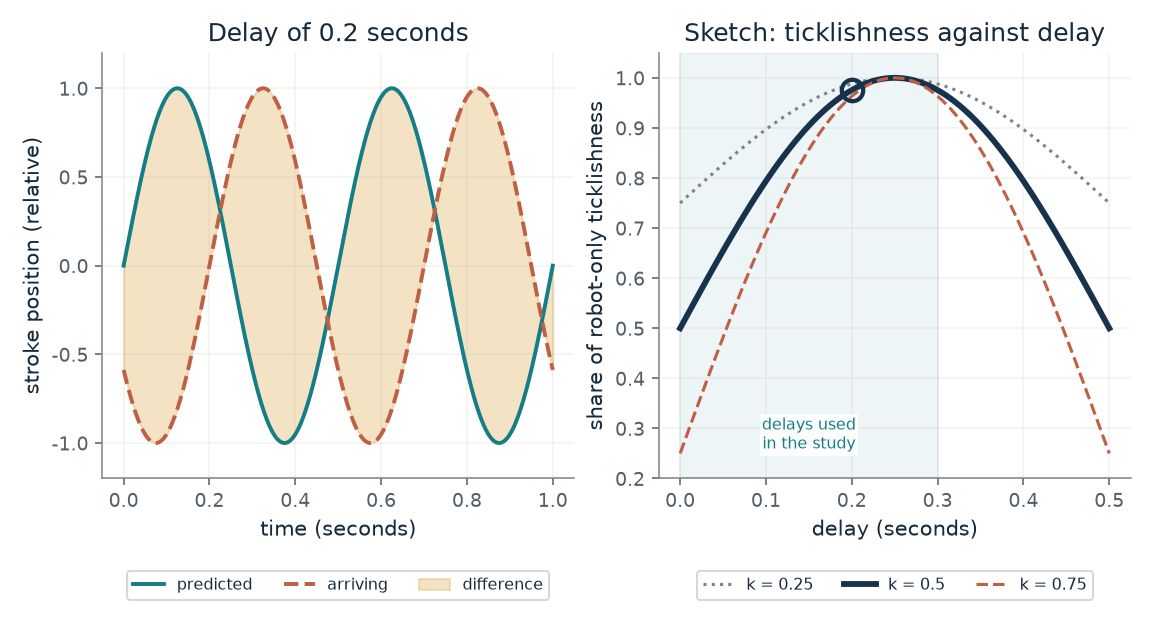

- **Prediction error (share of its largest):** 0.951
- **Share of robot-only ticklishness:** 0.976
- **Delay (seconds):** 0.2

A 0.2 second delay shifts a 2 per second stroke by 144 degrees of its cycle, so the prediction error is 0.951 of its largest value. If the touch is turned down by 0.5 when it matches the prediction, the share of robot-only ticklishness is 0.976.

Error = RMS of (sin(2 pi f t) - sin(2 pi f (t - d))) divided by sqrt(2) = |sin(pi f d)| = |sin(pi x 2 x 0.2)| = 0.951. Share = 1 - 0.5 x (1 - 0.951) = 0.976.

In [4]:
figure, values, explanation = delay_picture(**{'delay': 0.2, 'attenuation': 0.5})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Why would a late touch feel more ticklish?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Delay (seconds) = 0.2, Turn-down of a matched touch (k) = 0.5: At 0.2 seconds the prediction error is 0.951 of its largest value and ticklishness is 0.976 of the robot-only level, close to it, as the study found. At 0.1 it is lower (0.794) and at 0.4 it falls back (0.794). The study did not test 0.4 or 0.5.

**Takeaway:** A late touch matches the prediction badly, so it is turned down less. The sketch gives a rise that levels off near the study's delays, and its later behavior is untested.

**Why it matters:** The ratings fit the proposal that prediction error drives ticklishness, but they do not show subtraction or measure self-attribution. A model that fits one range can say nothing safe outside it.

**In brains and behavior:** The authors propose a forward model that turns the command into a predicted sensation. The study recorded ratings, not brain activity, and two of 16 volunteers noticed the delays; the chapter says the scans in a separate study of six do not show subtraction either.

**In machines:** The sketch is a specification of what the proposal's arithmetic gives for a sinusoid. It is not a fit to data.

**Where it applies:** A sinusoidal stroke and a turn-down in proportion to the match, both the companion's choices. The mathematics of a brain is a model. The sketch also predicts a return to full turn-down at 0.5 seconds, a delay the study did not use, so it is a property of the sketch, not a finding.

**Check your understanding:** At a delay of 0.25 seconds and turn-down 0.5, what share of the robot-only ticklishness remains?

<details><summary>Show the answer</summary>

|sin(pi x 2 x 0.25)| = 1, so the error is its largest and the share is 1 - 0.5 x 0 = 1: the touch is not turned down at all.

</details>

*Source: Chapter 30, A touch the volunteers made themselves felt more ticklish when it arrived late. A model sketch built by the companion on the chapter's forward-model proposal: a stroke repeated twice a second, a prediction made from the movement and a touch arriving d seconds late. The study's ratings are not reproduced: the chapter gives no values, only that ticklishness rose from no delay to 0.2 seconds and that at 0.2 and 0.3 seconds it was not significantly different from the robot-only touch (16 volunteers, delays of 0.1, 0.2 and 0.3).*

## C30-D04: How should a forecast and the senses share a hand's position?

A forecast from commands puts the hand at 10 cm and the senses put it at 20 cm. Where does the blend land?

Both numbers estimate the same position. The one with the smaller error variance gets more weight. The senses' weight is the forecast variance over the sum of the two. With equal variances each gets half. If the forecast is three times as noisy, the senses get three quarters of the weight, and the blend moves from 15 to 17.5.

$$
K=\frac{V_{\text{forecast}}}{V_{\text{forecast}}+V_{\text{senses}}},\qquad \hat{x}=x_{\text{forecast}}+K\,(x_{\text{senses}}-x_{\text{forecast}})
$$

**Symbols:** V: error variance: the spread of errors, smaller means more reliable; K: the Kalman gain, the share given to the senses; x-hat: the blended position, in cm

**Predict before looking:** If the forecast has three times the variance of the senses, predict the weight on the senses and the blend.

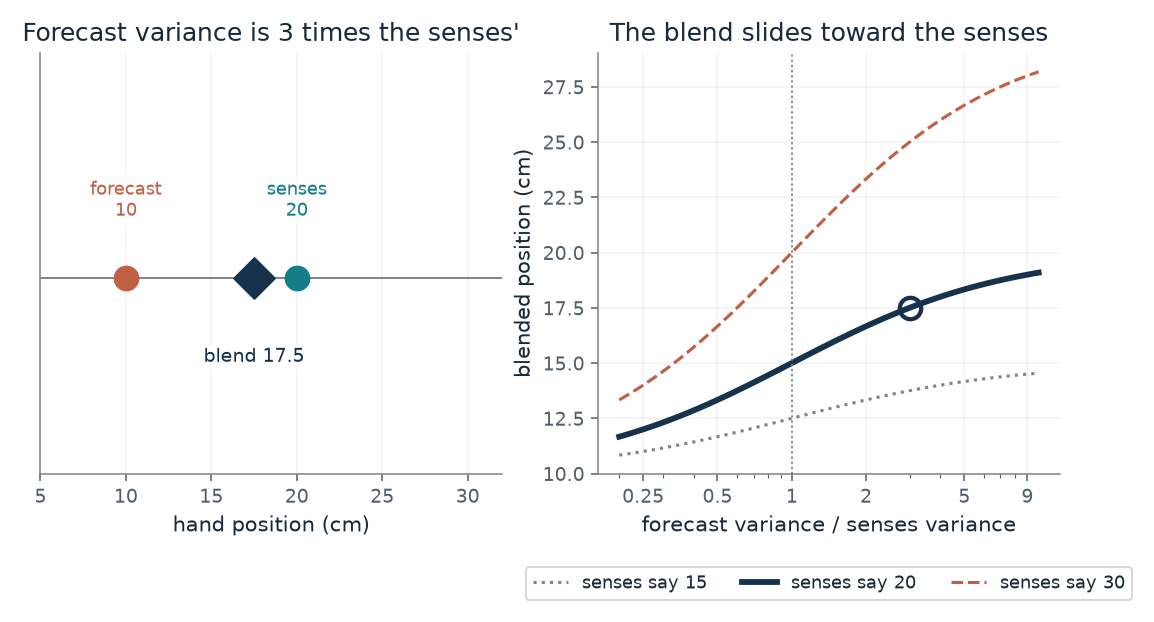

- **Weight on the senses (Kalman gain):** 0.75
- **Weight on the forecast:** 0.25
- **Blended position (cm):** 17.5

The forecast says 10 cm and the senses say 20 cm. With the forecast's variance 3 times the senses', the senses get weight 0.75 and the blend is 17.5 cm. This weight is the Kalman gain, not the prediction gain of the camera example.

Gain = 3/(3 + 1) = 0.75. Blend = 10 + 0.75 x (20 - 10) = 17.5.

In [5]:
figure, values, explanation = hand_picture(**{'ratio': 3, 'senses': 20})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt="How should a forecast and the senses share a hand's position?"))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Forecast variance / senses variance = 3, Where the senses put the hand (cm) = 20: The senses get weight three quarters and the blend is 17.5 cm. With equal variances (ratio 1) the blend is 15. The Kalman gain here is the share given to the senses, a different thing from the camera's prediction gain.

**Takeaway:** The blend moves toward whichever estimate has the smaller variance. The weight on the senses is the Kalman gain, not the prediction gain.

**Why it matters:** A person's sense of where the body is can be treated as an estimate, and an estimate can be pushed off. The chapter's studies show felt location can be shifted, not why.

**In brains and behavior:** A model: the chapter says engineering offers one way to model such an estimate. It does not show the brain runs this arithmetic.

**In machines:** A Kalman filter is a standard method that blends a forecast from commands with sensed feedback, weighted by reliability. Here the formula is a specification.

**Where it applies:** Both estimate the same position, neither is systematically high or low, and their errors are uncorrelated, as the chapter assumes. The senses' variance is set to 1.

**Check your understanding:** The forecast has variance 9 times the senses' and the senses say 20. What is the blend?

<details><summary>Show the answer</summary>

K = 9/10 = 0.9, so the blend is 10 + 0.9 x 10 = 19 cm.

</details>

*Source: Chapter 30, Stimulation gave a 43-year-old patient an out-of-body view of legs and lower trunk. The chapter's illustration with chosen numbers: a forecast at 10 cm, senses at 20 cm, equal variances giving 15 and a forecast with three times the variance giving 17.5. The other variance ratios and sensed positions are the companion's variations.*

## C30-D05: What would a shift in felt location mean as a weighting?

After synchronous stroking, 14 people drifted about 24 cm toward a body seen 2 metres ahead. What weight on the seen body would a blend need?

If the felt location is a blend of the own body at 0 and the seen body at 200 cm, a shift of 24.1 cm means a weight of 24.1 over 200. The weight is the variance of the own estimate over the sum of the two variances, so the implied ratio is (1 minus w) over w. This turns a reported number into a modeling statement. The study makes no such statement.

$$
w=\frac{\text{shift}}{200\ \text{cm}},\qquad \frac{V_{\text{seen}}}{V_{\text{own}}}=\frac{1-w}{w}
$$

**Symbols:** shift: the average drift toward the seen body, in cm; w: the weight on the seen body in a blend of own location (0) and seen body (200 cm); V_seen / V_own: the variance ratio that a blend would need to give that weight

**Predict before looking:** Predict the weight on the seen body that a 24 cm shift of a 200 cm gap would imply.

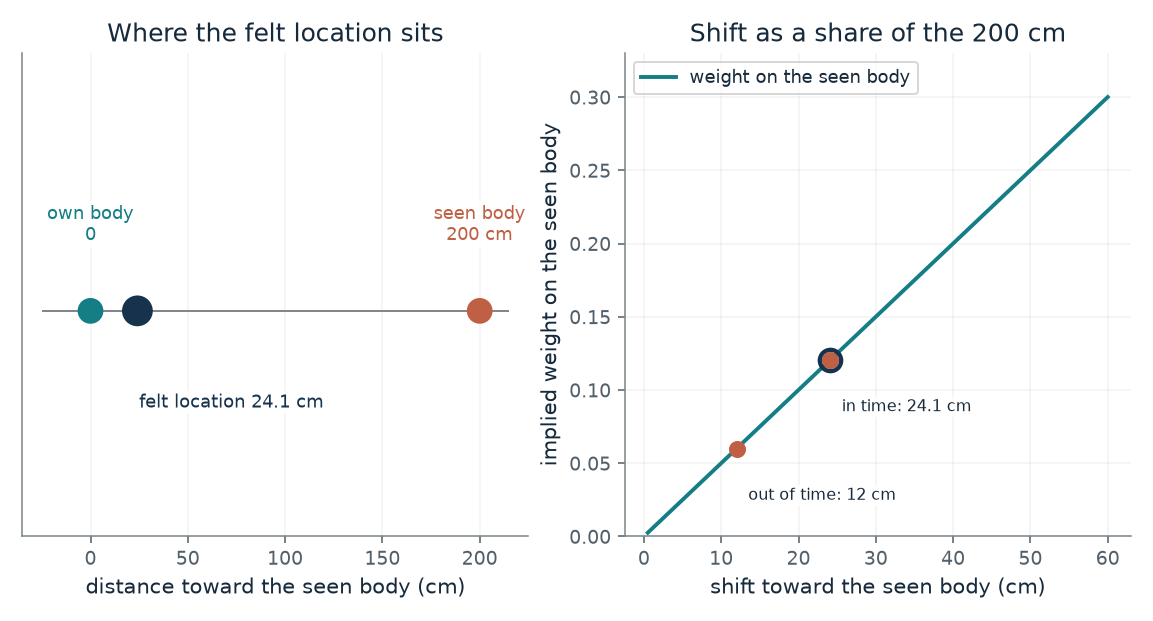

- **Shift (cm):** 24.1
- **Implied weight on the seen body:** 0.121
- **Implied variance ratio, seen body over own:** 7.3

If the felt location were a blend of the own body (0 cm) and the seen body (200 cm), a shift of 24.1 cm would mean a weight of 0.121 on the seen body. This is the companion's reading, not the study's claim, and the 12 cm shift was not a reliable shift from baseline.

Weight = shift / 200 = 24.1/200 = 0.121. Variance ratio = (1 - w)/w = 7.3.

In [6]:
figure, values, explanation = felt_location_picture(**{'shift': 24.1})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='What would a shift in felt location mean as a weighting?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Shift toward the seen body (cm) = 24.1: The weight is about 0.12, a variance ratio of about 7.3: the seen body would need about seven times the variance of the own-body estimate. The out-of-time shift of about 12 cm gives about 0.06, though it was not a reliable shift from baseline.

**Takeaway:** A 24 cm shift across 200 cm corresponds to a modest weight on the seen body. This restates a reported number as a model parameter and shows nothing about how the brain produces the shift.

**Why it matters:** A model can express a shift, but fitting a number is not an explanation. Blanke's patient was one person at one site, and Lenggenhager's stroking involved no command to move.

**In brains and behavior:** Stimulation at one site gave one patient a view of the legs and lower trunk from above; the chapter says the authors suggest a failure to combine body and balance signals. These are reports of experience and not measurements of a mechanism.

**In machines:** A specification: any blend gives a weight from a variance ratio. No machine here has these experiences.

**Where it applies:** The felt location is treated as a blend of two points, with the shift as a fraction of the distance. The study's measure is where people walked back to, and the chapter says these studies show felt location can be shifted, not why. The study reports no group spread here, so none is shown.

**Check your understanding:** For a 24.1 cm shift, what is the implied weight, to two decimal places?

<details><summary>Show the answer</summary>

24.1/200 = 0.1205, about 0.12.

</details>

*Source: Chapter 30, Stimulation gave a 43-year-old patient an out-of-body view of legs and lower trunk. Reported result: Lenggenhager and colleagues' first study (14 people): about 24 cm closer to the seen body after stroking in time, about 12 cm out of time (not a reliable shift from baseline), the seen body two metres ahead. The weighting reading is the companion's, not the study's or the chapter's.*

## C30-D06: Why does an explorer rewarded for surprise need the right features?

An agent is paid for prediction error. What happens to its reward when part of its view is static it can never predict?

The reward grows with the squared miss of the forward model's prediction of the next features. Door pixels become predictable with training, so their part of the reward shrinks. Static stays unpredictable, so its part does not. If the features keep the static, the static eventually dominates the reward. If learning the features favors what the agent's actions explain, the static tends to drop out.

$$
r_t=\frac{\eta}{2}\,\bigl\|\hat\phi(s_{t+1})-\phi(s_{t+1})\bigr\|^{2}
$$

**Symbols:** phi(s): the learned features of a situation s; phi-hat: the forward model's prediction of the next features; eta: a positive scale, 1 here; r_t: the internal reward at step t

**Predict before looking:** With 40 percent static in raw pixels, predict whether the reward ever falls toward zero as the door becomes predictable.

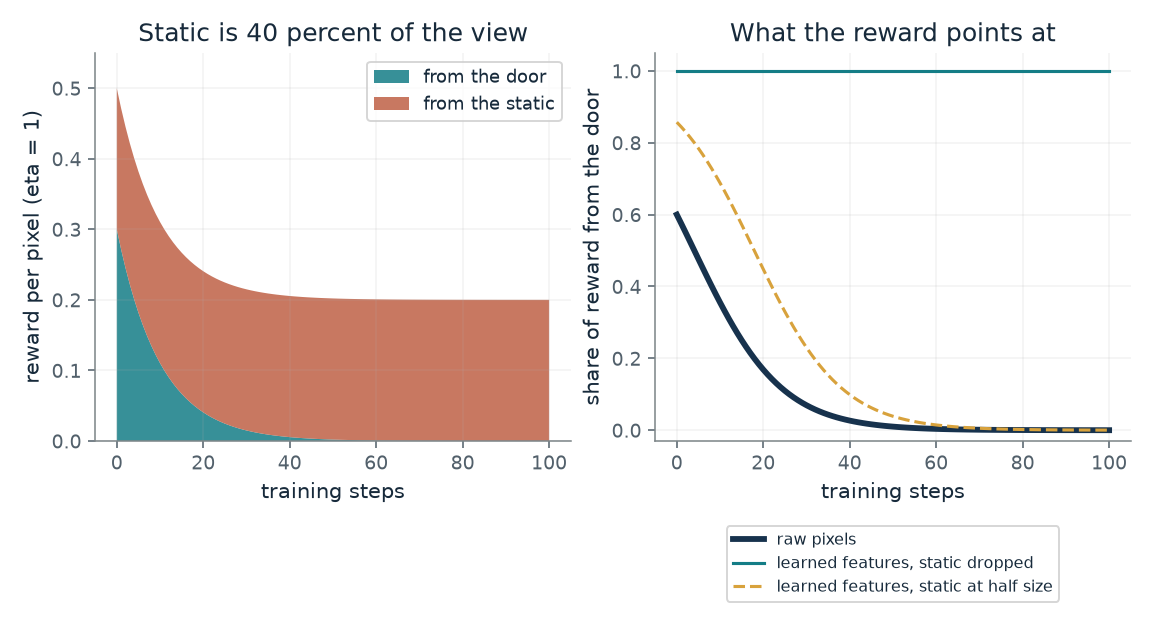

- **Reward at step 0:** 0.5
- **Reward at step 100:** 0.2
- **Share from the door at step 100:** 6.81e-05

With 40 percent static and raw pixels, the reward starts at 0.5 and is 0.2 at step 100. Static keeps the reward high however long the agent trains.

r = (eta/2) x (0.6 x e^(-2 t/20) + 0.4 x 1). At t = 100 the door part is 1.36e-05 and the static part is 0.2.

In [7]:
figure, values, explanation = curiosity_picture(**{'noise_share': 0.4, 'kind': 'raw pixels'})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Why does an explorer rewarded for surprise need the right features?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Share of the view that is static = 0.4, What the features keep = raw pixels: In raw pixels the reward settles at 0.2, all from the static, however long the agent trains: the curiosity trap. With learned features that drop the static, the reward falls toward zero as the door becomes predictable and everything left comes from the door.

**Takeaway:** A reward for prediction error in raw pixels can be held up by noise the agent cannot affect. The result depends on which features are learned as much as on the size of the error.

**Why it matters:** The chapter says the reward measures prediction error in learned features, not information gain. Whether the agent keeps exploring depends on what the features keep.

**In brains and behavior:** None. The paper does not mention brains, corollary discharge or monkeys.

**In machines:** The authors report the method still reached the goal with 40 percent of the view replaced by white noise, with a sparse external reward for reaching it. The chapter says that result is about noise the agent cannot affect.

**Where it applies:** A one-line stand-in for the forward model: the door's error shrinks smoothly, the static's error stays at 1. The chapter says the learned features are not guaranteed to filter perfectly. A simulation here is a computation with a fixed formula, not a measurement of any agent.

**Check your understanding:** With 40 percent static in raw pixels and eta = 1, what reward remains from the static at any step?

<details><summary>Show the answer</summary>

(1/2) x 0.4 x 1 = 0.2, constant, because the static's prediction error never shrinks.

</details>

*Source: Chapter 30, An explorer paid for surprise worked despite noise it could not influence. The reward formula of Pathak and colleagues (2017) as the chapter prints it. The room with static and a door follows the chapter's constructed picture. The decay time of 20 steps, the static fraction and the half-size static are the companion's invented values; the paper's maze test with 40 percent white noise is reported only in words.*

## Bring it to your own question

When a system subtracts a prediction of its own move, check the prediction's gain and show the operator both the prediction and the observation before treating the leftover as the world.

Use the `mmi-ch30-modeling-yourself` skill to choose a relevant equation, work with your inputs, and interpret the result. The skill should explain the assumptions and distinguish an illustration from evidence about your particular situation.